# Binned evaluation
Plots the CSV files written by `helixer/evaluation/binned_eval.py`, which breaks the base-wise scores of
a predictions file down into bins:
- `position_bins.csv`: scores per bin of base position within the subsequence
- `gene_length_bins.csv`: scores per bin of gene length

Each row of both files is one bin. It holds the bin range `[bin_start, bin_end)` in bp, the number of
evaluated bases (`n_bases`), the accuracy, precision, recall and F1 of every class (`ig`, `utr`,
`cds`, `intron`) and composite score (`legacy_cds`, `sub_genic`, `genic`), e.g. `cds_recall`, and
the confusion matrix counts, e.g. `ig_ref_cds_pred` for intergenic reference bases predicted as CDS.
Bases with a sample weight of 0 (padding, annotation errors) are not evaluated.

`binned_eval.py` writes both files to one output directory per run. For example, for predictions of
the same test data without and with overlapping:
```shell script
mkdir -p binned_eval/no_overlap binned_eval/overlap
python helixer/evaluation/binned_eval.py -d test_data.h5 -p predictions.h5 -o binned_eval/no_overlap
python helixer/evaluation/binned_eval.py -d test_data.h5 -p predictions_overlap.h5 -o binned_eval/overlap
```
`python helixer/evaluation/binned_eval.py --help` lists the bin options.

This notebook needs Jupyter, pandas and matplotlib, which are not dependencies of Helixer:
```shell script
pip install notebook pandas matplotlib
```

The example plots here show the comparison between predictions with and without overlap enabled and the reference for the README's example _Arabidopsis lyrata_ chromosome 8 from Ensembl.

> Note: The h5 files for the predictions and the refernce h5 file creted from a GeenuFF sqlite3 file with geenuff2h5.py need to have the same shape (the same number of subsequences, the same subsequence length and 4 classes).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# run label -> output directory of binned_eval.py
RUNS = {
    'without overlap': 'binned_eval/no_overlap',
    'with overlap': 'binned_eval/overlap',
}
position = {label: pd.read_csv(Path(path) / 'position_bins.csv') for label, path in RUNS.items()}
gene_length = {label: pd.read_csv(Path(path) / 'gene_length_bins.csv') for label, path in RUNS.items()}

In [2]:
def plot_runs(ax, dfs, x, metrics, ylim):
    """Plots each metric of each run; the color marks the run, the line style the metric."""
    colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    linestyles = ['-', '--', ':', '-.']
    for color, (label, df) in zip(colors, dfs.items()):
        for linestyle, metric in zip(linestyles, metrics):
            ax.plot(x(df), df[metric], color=color, linestyle=linestyle, label=f'{label}: {metric}')
    ax.set_ylim(ylim)
    ax.set_ylabel('score')
    ax.legend()

## Scores by position in the subsequence
Helixer predicts on subsequences of a fixed length (e.g. 21384 bp for land plants). `--position-bins`
(default 100) divides this length into equally sized bins, and every base is counted in the bin of its
position within its subsequence. Bases near the subsequence ends have less sequence context on one
side, so lower scores in the first and last bins show this edge effect. Predicting with `--overlap`
should flatten the curve.

Each bin is plotted at its center. Every column of `position_bins.csv` can be added to `metrics`,
e.g. `'cds_f1'` or `'intron_recall'`.

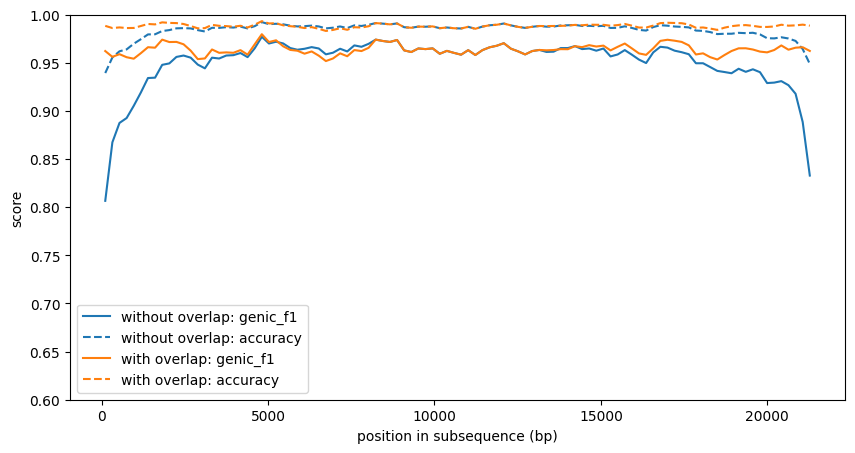

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
plot_runs(ax, position, lambda df: (df.bin_start + df.bin_end) / 2, ['genic_f1', 'accuracy'], ylim=(0.6, 1))
ax.set_xlabel('position in subsequence (bp)')
plt.show()

## Scores by gene length
The data file holds `data/gene_lengths`: for every base, the length of the longest pre-mRNA
overlapping it, so UTRs and introns count towards it. Intergenic bases have a gene length of 0.
`binned_eval.py` sorts the bases into bins by this value.

### Gene length edges
`--gene-length-edges` sets where one bin ends and the next one begins; each edge is the lower end
(`bin_start`) of a bin. The first two bins are always added: `[0, 1)` for the intergenic bases and
`[1, first edge)`. The last bin has no upper end (empty `bin_end`). The default edges
`500 1000 2000 5000 10000 20000 50000 100000` give these bins:

| bin_start | bin_end | bases in                          |
|----------:|--------:|:----------------------------------|
|         0 |       1 | intergenic regions                |
|         1 |     500 | genes shorter than 500 bp         |
|       500 |    1000 | genes of 500 to 999 bp            |
|      1000 |    2000 | genes of 1000 to 1999 bp          |
|       ... |     ... | ...                               |
|    100000 |         | genes of 100000 bp or longer      |

For example, `--gene-length-edges 1000 10000` gives four bins: intergenic, genes shorter than 1 kb,
genes of 1 to 10 kb and genes of 10 kb or longer.

The bins count bases, not genes: a 50 kb gene adds 100 times as many bases to its bin as a 500 bp
gene. All runs compared here need the same `--gene-length-edges`.

### Recall per gene length bin
All reference bases in the bins after `[0, 1)` are genic (UTR, CDS or intron). For these bins:
- **Recall is complete.** E.g. `cds_recall` in the 1000-1999 bin is the fraction of reference CDS
  bases in genes of that length that are predicted as CDS. Both kinds of errors count: bases
  predicted as intergenic (missed gene parts) and bases predicted as another genic class.
- **Precision is too high.** Precision counts how many of the bases predicted as a class are correct.
  Genic predictions where the reference is intergenic (additional genes, genes or UTRs extending too
  far) are wrong, but these bases have a gene length of 0 and are counted in the `[0, 1)` bin only.
  Precision in the genic bins only includes confusions between UTR, CDS and intron, and F1 is too
  high as well. The next section shows these false positives.

The plot therefore shows the recall per class. In these bins, `genic_recall` equals the accuracy. The
bar plot shows the number of evaluated bases per bin of the first run; scores of bins with few bases
are less reliable. Empty bins have no score.

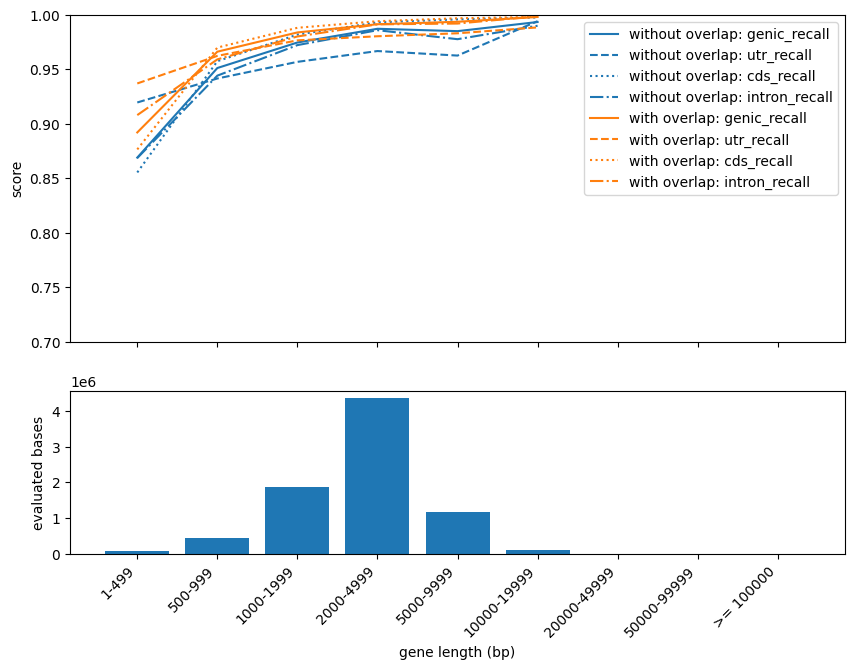

In [4]:
genic = {label: df[df.bin_start > 0].reset_index(drop=True) for label, df in gene_length.items()}
first = next(iter(genic.values()))
bin_labels = [f'{start}-{int(end) - 1}' if pd.notna(end) else f'>= {start}'
              for start, end in zip(first.bin_start, first.bin_end)]

fig, (ax, ax_n) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, height_ratios=[2, 1])
plot_runs(ax, genic, lambda df: df.index, ['genic_recall', 'utr_recall', 'cds_recall', 'intron_recall'], ylim=(0.7,1))
ax_n.bar(first.index, first.n_bases)
ax_n.set_ylabel('evaluated bases')
ax_n.set_xticks(first.index, bin_labels, rotation=45, ha='right')
ax_n.set_xlabel('gene length (bp)')
plt.show()

### Genic bases predicted as intergenic
The table shows per gene length bin and run how many genic reference bases were predicted as
intergenic, i.e. gene parts the model missed: the sum of `utr_ref_ig_pred`, `cds_ref_ig_pred` and
`intron_ref_ig_pred`, and its share of the evaluated bases of the bin. A high share in the bins of
short genes points to short genes that are missed completely or predicted too short (Very short annotated
genes are more often questionable annotations, such as fragments or small ORFs.). Like all values
here, these are bases, not genes; the number of genes per bin is not part of the CSV files.

In [5]:
columns = {}
for label, df in genic.items():
    n_missed = df.utr_ref_ig_pred + df.cds_ref_ig_pred + df.intron_ref_ig_pred
    columns[(label, 'genic bases')] = df.n_bases
    columns[(label, 'predicted intergenic')] = n_missed
    columns[(label, 'share')] = n_missed / df.n_bases
missed = pd.DataFrame(columns)
missed.index = bin_labels
missed

without overlap                                with overlap  \
                genic bases predicted intergenic     share  genic bases   
1-499                 71276                 7363  0.103303        71276   
500-999              442550                14023  0.031687       442550   
1000-1999           1876679                27395  0.014598      1876679   
2000-4999           4347864                25341  0.005828      4347864   
5000-9999           1173700                12462  0.010618      1173700   
10000-19999          122192                  321  0.002627       122192   
20000-49999               0                    0       NaN            0   
50000-99999               0                    0       NaN            0   
>= 100000                 0                    0       NaN            0   

                                            
            predicted intergenic     share  
1-499                       5885  0.082566  
500-999                     8499  0.019205  
1000-1999                  13188  0.007027  
2000-4999                  11826  0.002720  
5000-9999                   2946  0.002510  
10000-19999                   33  0.000270  
20000-49999                    0       NaN  
50000-99999                    0       NaN  
>= 100000                      0       NaN

### Intergenic bases predicted as genic
The `[0, 1)` bin holds all intergenic reference bases, so all genic predictions where the reference
has no gene end up here, in the counts `ig_ref_utr_pred`, `ig_ref_cds_pred` and `ig_ref_intron_pred`.
The table shows per run how many intergenic bases were predicted as genic, overall and per predicted
class. `share predicted genic` equals `1 - ig_recall` of this bin. The split by class hints at the
kind of error, e.g. many bases predicted as UTR point to UTRs extending too far, many bases predicted
as CDS or intron to additional or too long coding regions.

In [6]:
genic_classes = ['utr', 'cds', 'intron']
rows = {}
for label, df in gene_length.items():
    intergenic = df.iloc[0]  # bin [0, 1)
    predicted = {cls: int(intergenic[f'ig_ref_{cls}_pred']) for cls in genic_classes}
    n_genic = sum(predicted.values())
    rows[label] = {'intergenic bases': int(intergenic.n_bases), 'predicted genic': n_genic,
                   'share predicted genic': n_genic / intergenic.n_bases,
                   **{f'predicted {cls}': n for cls, n in predicted.items()}}
pd.DataFrame.from_dict(rows, orient='index')

,intergenic bases,predicted genic,share predicted genic,predicted utr,predicted cds,predicted intron
without overlap,37796158,585378,0.015488,106770,228711,249897
with overlap,37796158,441824,0.011690,79469,180512,181843
